In [1]:
import pickle
import os
import mdtraj as md
import numpy as np
import matplotlib.pyplot as plt


N_TIMESTEP_IN_REPLICA = 101
TEMPERATURE = 300

pickle_dir = "./pickle-cache/energy-dissociation_3d"
if not os.path.exists(pickle_dir):
    os.mkdir(pickle_dir)

pacs_com_distances = []
pacs_com_vectors = []
for trial in range(50):
    pickle_com_distances = pickle.load(open(f"./pickle-cache/com-features/pacs_com_distances_{trial}.pickle", "rb"))
    pacs_com_distances.append(pickle_com_distances.reshape((-1, N_TIMESTEP_IN_REPLICA, 1)))
    pickle_com_vectors = pickle.load(open(f"./pickle-cache/com-features/pacs_com_vectors_{trial}.pickle", "rb"))
    pacs_com_vectors.append(pickle_com_vectors.reshape((-1, N_TIMESTEP_IN_REPLICA, 3)))

trajs = pacs_com_vectors

In [2]:
from sklearn.cluster import KMeans
import matplotlib


def cluster_trajs(trajs, n_clusters):
    clustering_model = KMeans(
        n_clusters=n_clusters,
        init="k-means++",
        n_init=10,
        max_iter=int(1e10),
        tol=1e-10,
        verbose=0,
        random_state=1,
        copy_x=True,
        algorithm="lloyd"
    )
    trajs_concat = np.concatenate(trajs)
    clustered_trajs_concat = clustering_model.fit_predict(trajs_concat)
    return clustered_trajs_concat.reshape(len(trajs), N_TIMESTEP_IN_REPLICA), clustering_model.cluster_centers_


def plot_clusters(ax, trajs, clustered_trajs, cluster_centers):
    trajs_concat = np.concatenate(trajs)
    clustered_trajs_concat = np.concatenate(clustered_trajs)

    ax.scatter(trajs_concat[:, 0], trajs_concat[:, 1], s=0.1, c=[matplotlib.cm.tab20(i_cluster%20) for i_cluster in clustered_trajs_concat])
    for cluster_center in cluster_centers:
        ax.scatter(cluster_center[0], cluster_center[1], color="black", s=5)

In [3]:
from deeptime.markov import TransitionCountEstimator
from deeptime.markov.msm import MaximumLikelihoodMSM
from deeptime.markov.tools import estimation
from deeptime.util.validation import implied_timescales
import deeptime.plots


def construct_msm(clustered_trajs, lagtimes):
    msm_models = {}
    stationary_distributions = {}

    for lagtime in lagtimes:
        count_estimator = TransitionCountEstimator(
            lagtime=lagtime,
            count_mode="sliding",
            n_states=None,
            sparse=False,
        )
        count_estimator.fit(clustered_trajs)
        count_model = count_estimator.fetch_model()

        msm_constructor = MaximumLikelihoodMSM(
            reversible=True,
            stationary_distribution_constraint=None,
            sparse=False,
            allow_disconnected=False,
            maxiter=int(1e10),
            maxerr=1e-10,
            connectivity_threshold=0,
            transition_matrix_tolerance=1e-10,
            lagtime=None,
            use_lcc=False,
        ) 

        try:
            msm_constructor.fit(count_model)
        except:
            continue

        msm_models[lagtime] = msm_constructor.fetch_model()
        largest_connected_set = estimation.largest_connected_set(count_model.count_matrix, directed=True)
        stationary_distributions[lagtime] = np.zeros(np.max(clustered_trajs)+1)
        stationary_distributions[lagtime][largest_connected_set] = msm_models[lagtime].stationary_distribution

    return msm_models, stationary_distributions


def plot_implied_timescales(ax, msm_models):
    deeptime.plots.plot_implied_timescales(
        implied_timescales(list(msm_models.values())),
        n_its=10,
        ax=ax,
        process=None,
        show_mle=True,
        show_sample_mean=True,
        show_sample_confidence=True,
        show_cutoff=True,
        sample_confidence=0.95,
        colors=None,
    )
    ax.set_xlim(0, np.max(list(msm_models.keys())))
    ax.set_yscale("log")

In [4]:
n_clusters_candidates = [100, 80, 60, 40, 20]

if False:
    clustered_trajs = [None for _ in range(len(trajs))]
    cluster_centers = [None for _ in range(len(trajs))]
    
    for trial in range(len(trajs)):
        clustered_trajs[trial] = {}
        cluster_centers[trial] = {}
        for i_clusters, n_clusters in enumerate(n_clusters_candidates):
            print(trial, n_clusters)
            clustered_trajs[trial][n_clusters], cluster_centers[trial][n_clusters] = cluster_trajs(trajs[trial], n_clusters)

    pickle.dump(clustered_trajs, open(f"{pickle_dir}/clustered_trajs.pickle", "wb"))
    pickle.dump(cluster_centers, open(f"{pickle_dir}/cluster_centers.pickle", "wb"))

clustered_trajs = pickle.load(open(f"{pickle_dir}/clustered_trajs.pickle", "rb"))
cluster_centers = pickle.load(open(f"{pickle_dir}/cluster_centers.pickle", "rb"))


# fig_cluster, ax_cluster = plt.subplots(len(trajs), len(n_clusters_candidates))
# fig_cluster.set_size_inches(4*len(n_clusters_candidates), 4*len(trajs))

# for trial in range(len(trajs)):
#     for i_clusters, n_clusters in enumerate(n_clusters_candidates):
#         plot_clusters(ax_cluster[trial][i_clusters], trajs[trial], clustered_trajs[trial][n_clusters], cluster_centers[trial][n_clusters])
#         ax_cluster[trial][i_clusters].set_title(f"{trial}-{n_clusters}")



In [5]:
if False:
    msm_models = [None for _ in range(len(trajs))]
    stationary_distributions = [None for _ in range(len(trajs))]
    
    for trial in range(len(trajs)):
        msm_models[trial] = {}
        stationary_distributions[trial] = {}
        for i_clusters, n_clusters in enumerate(n_clusters_candidates):
            print(trial, n_clusters)
            msm_models[trial][n_clusters], stationary_distributions[trial][n_clusters] = construct_msm(clustered_trajs[trial][n_clusters], range(2, int(N_TIMESTEP_IN_REPLICA/2), 2))

    pickle.dump(msm_models, open(f"{pickle_dir}/msm_models.pickle", "wb"))
    pickle.dump(stationary_distributions, open(f"{pickle_dir}/stationary_distributions.pickle", "wb"))

msm_models = pickle.load(open(f"{pickle_dir}/msm_models.pickle", "rb"))
stationary_distributions = pickle.load(open(f"{pickle_dir}/stationary_distributions.pickle", "rb"))


fig_its, ax_its = plt.subplots(len(trajs), len(n_clusters_candidates))
fig_its.set_size_inches(4*len(n_clusters_candidates), 4*len(trajs))

for trial in range(len(trajs)):
    for i_clusters, n_clusters in enumerate(n_clusters_candidates):
        plot_implied_timescales(ax_its[trial][i_clusters], msm_models[trial][n_clusters])
        ax_its[trial][i_clusters].set_title(f"{trial}-{n_clusters}")

In [6]:
import scipy.constants
from scipy.spatial import ConvexHull


def calculate_pmf(stationary_distributions):
    pmf = -np.log(stationary_distributions/max(stationary_distributions))
    pmf *= scipy.constants.Boltzmann
    pmf *= TEMPERATURE
    pmf *= scipy.constants.Avogadro
    pmf /= scipy.constants.calorie
    pmf /= 1000
    return pmf


def calculate_pmf_plot(cluster_centers, pmf, unbound_threshold):
    com_distances_cluster_centers = np.linalg.norm(cluster_centers, axis=1)
    indices_order = np.argsort(com_distances_cluster_centers)
    ordered_pmf = pmf[indices_order]
    ordered_cluster_centers = com_distances_cluster_centers[indices_order]

    pmf_baseline = []
    for i_cluster_center, (cluster_center, _pmf) in enumerate(zip(ordered_cluster_centers, ordered_pmf)):
        if unbound_threshold < cluster_center and np.isfinite(_pmf):
            pmf_baseline.append(_pmf)
    ordered_pmf -= np.mean(pmf_baseline)

    return ordered_cluster_centers, ordered_pmf


def plot_pmf(ax, ordered_cluster_centers, ordered_pmf, xmin, xmax, ymin, ymax, bound_threshold=None, unbound_threshold=None):
    # ax.hlines(0, xmin=xmin, xmax=xmax, color="black")
    if bound_threshold != None and unbound_threshold != None:
        ax.vlines(bound_threshold,   ymin=ymin, ymax=ymax, color="black", linestyles="--")
        ax.vlines(unbound_threshold, ymin=ymin, ymax=ymax, color="black", linestyles="--")

    ax.plot(ordered_cluster_centers, ordered_pmf)
    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)


def calculate_g_pmf(cluster_centers, stationary_distributions, bound_threshold, unbound_threshold):
    bound_probability = 0
    unbound_probability = 0

    for cluster_center, stationary_distribution in zip(cluster_centers, stationary_distributions):
        com_distances_cluster_centers = np.linalg.norm(cluster_center)
        
        if com_distances_cluster_centers < bound_threshold:
            bound_probability += stationary_distribution
        if  unbound_threshold < com_distances_cluster_centers:
            unbound_probability += stationary_distribution

    g_pmf = -np.log(bound_probability/unbound_probability)
    g_pmf *= scipy.constants.Boltzmann
    g_pmf *= TEMPERATURE
    g_pmf *= scipy.constants.Avogadro
    g_pmf /= scipy.constants.calorie
    g_pmf /= 1000

    return g_pmf


def calculate_volume_correction(com_vectors, unbound_threshold):
    unbound_com_vectors = com_vectors[unbound_threshold < np.linalg.norm(com_vectors, axis=2)]
    hull = ConvexHull(unbound_com_vectors)

    volume_correction = -np.log(hull.volume/1.661)
    volume_correction *= scipy.constants.Boltzmann
    volume_correction *= TEMPERATURE
    volume_correction *= scipy.constants.Avogadro
    volume_correction /= scipy.constants.calorie
    volume_correction /= 1000

    return volume_correction

In [7]:
pmfs = [None for _ in range(len(trajs))]

for trial in range(len(trajs)):
    pmfs[trial] = {}
    for i_clusters, n_clusters in enumerate(n_clusters_candidates):
        pmfs[trial][n_clusters] = {}
        for lagtime in stationary_distributions[trial][n_clusters]:
            try:
                pmfs[trial][n_clusters][lagtime] = calculate_pmf(stationary_distributions[trial][n_clusters][lagtime])
            except:
                continue

/tmp/ipykernel_790160/577652475.py:6: RuntimeWarning: divide by zero encountered in log
  pmf = -np.log(stationary_distributions/max(stationary_distributions))




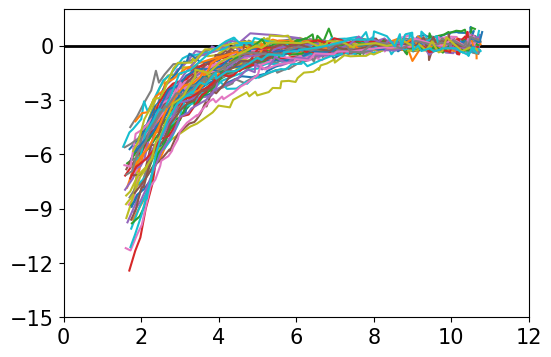

In [8]:
bound_thresholds = [2.2 for _ in range(len(trajs))]
unbound_thresholds = [
    6.5, 4.5, 5, 5.5, 3.5,
    6, 5, 4, 5, 4.5,
    3, 5, 5, 7, 7,
    5.5, 4, 6.5, 6, 7,
    8, 6, 6, 4.5, 4.5,
    4.5, 7, 8, 8, 6.5,
    6, 5, 5.5, 5.5, 7,
    6, 5, 5.5, 3.5, 4,
    5, 5, 5, 5, 5.5,
    6, 6.5, 5.5, 5.5,6,
]

n_clusters = [60 for _ in range(len(trajs))]
lagtimes   = [20 for _ in range(len(trajs))]

fig_trial, ax_trial = plt.subplots(1, len(trajs))
fig_trial.set_size_inches(3*len(trajs), 2)

fig_all, ax_all = plt.subplots(1,1)
fig_all.set_size_inches(6, 4)

ax_all.hlines(0, xmin=0, xmax=12, color="black", linewidth=2)

for trial in range(len(trajs)):
    ordered_cluster_centers, ordered_pmf = calculate_pmf_plot(cluster_centers[trial][n_clusters[trial]], pmfs[trial][n_clusters[trial]][lagtimes[trial]], unbound_thresholds[trial])

    plot_pmf(ax_all,          ordered_cluster_centers, ordered_pmf, 0, 12, -15, 2)
    plot_pmf(ax_trial[trial], ordered_cluster_centers, ordered_pmf, 0, 12, -15, 2, bound_threshold=bound_thresholds[trial], unbound_threshold=unbound_thresholds[trial])
    ax_trial[trial].set_title(trial)

ax_all.set_xticks(range(0, 13, 2))
ax_all.tick_params(axis='x', labelsize=15)
ax_all.set_yticks(range(-15, 3, 3))
ax_all.tick_params(axis='y', labelsize=15)

In [9]:
g_pmfs = np.zeros(len(trajs))
volume_corrections = np.zeros(len(trajs))
for trial in range(len(trajs)):
    g_pmfs[trial] = calculate_g_pmf(cluster_centers[trial][n_clusters[trial]], stationary_distributions[trial][n_clusters[trial]][lagtimes[trial]], bound_thresholds[trial], unbound_thresholds[trial])
    volume_corrections[trial] = calculate_volume_correction(pacs_com_vectors[trial], unbound_thresholds[trial])

g_stds = g_pmfs + volume_corrections

for trial in range(len(trajs)):
    print(trial, g_pmfs[trial], volume_corrections[trial], g_stds[trial])
print()
print("mean", g_pmfs.mean(), volume_corrections.mean(), g_stds.mean())
print("std ", g_pmfs.std(),  volume_corrections.std(),  g_stds.std())
g_stds

0 -3.8229137685364285 -2.3871992530499293 -6.210113021586357
1 -5.854414815557394 -2.4976901419156605 -8.352104957473054
2 -4.778821483544491 -2.45392221378687 -7.232743697331362
3 -5.132400924456297 -2.4668815716979533 -7.599282496154251
4 -5.870760134085447 -2.4926922756813172 -8.363452409766765
5 -4.94047031268742 -2.263336148283845 -7.203806460971265
6 -6.773281659569277 -2.6743866041867324 -9.44766826375601
7 -2.400691345799169 -2.6025299430829576 -5.003221288882127
8 -7.417089828792335 -2.608093654347719 -10.025183483140054
9 -3.5958052264331926 -2.655975022336515 -6.251780248769707
10 -3.9268809801612914 -2.7318588108974065 -6.658739791058698
11 -7.644385284768655 -2.4865123674537215 -10.130897652222377
12 -6.731994727760392 -2.492173279415948 -9.22416800717634
13 -10.450140116050534 -2.3736774645395387 -12.823817580590072
14 -7.816270083662801 -2.3954939253609138 -10.211764009023716
15 -4.929334531586924 -2.2428921983581582 -7.172226729945082
16 -4.880610663098907 -2.4980939602

array([ -6.21011302,  -8.35210496,  -7.2327437 ,  -7.5992825 ,
        -8.36345241,  -7.20380646,  -9.44766826,  -5.00322129,
       -10.02518348,  -6.25178025,  -6.65873979, -10.13089765,
        -9.22416801, -12.82381758, -10.21176401,  -7.17222673,
        -7.37870462,  -8.9514507 ,  -7.23379183,  -8.18048749,
        -9.56584585,  -7.58882361,  -6.76926359,  -6.84996047,
        -7.65822051,  -8.0446038 ,  -7.61695259,  -6.32451076,
        -9.30306933, -10.48809448,  -6.2163131 ,  -4.73585379,
        -6.50986791,  -6.17124558,  -6.65776636,  -8.62376698,
        -6.18016257,  -7.00256408,  -6.29637976,  -7.05484072,
        -6.38172276,  -7.34168571, -10.47228009,  -7.77215668,
        -9.82198603, -10.19334507, -12.08947939,  -7.86607704,
        -8.89710202, -11.64381751])

In [10]:
g_stds_ordered = []
for trial, g_std in enumerate(g_stds):
    g_stds_ordered.append((trial,  g_std))
g_stds_ordered.sort(key=lambda x: x[1], reverse=True)

print(g_stds_ordered)
print(f"[{','.join([str(val[0]) for val in g_stds_ordered])}]")

[(31, -4.735853785240314), (7, -5.003221288882127), (33, -6.1712455762377), (36, -6.180162572537599), (0, -6.210113021586357), (30, -6.21631310048984), (9, -6.251780248769707), (38, -6.296379757436588), (27, -6.324510759445658), (40, -6.381722757539423), (32, -6.509867909636235), (34, -6.65776635690953), (10, -6.658739791058698), (22, -6.769263592911873), (23, -6.849960467272739), (37, -7.002564078210507), (39, -7.054840715656249), (15, -7.172226729945082), (5, -7.203806460971265), (2, -7.232743697331362), (18, -7.233791833157946), (41, -7.341685708162548), (16, -7.378704623377679), (21, -7.588823614916845), (3, -7.599282496154251), (26, -7.6169525908216595), (24, -7.658220505525985), (43, -7.7721566819200385), (47, -7.86607703613511), (25, -8.044603801531192), (19, -8.180487490175555), (1, -8.352104957473054), (4, -8.363452409766765), (35, -8.62376698137324), (48, -8.897102024270128), (17, -8.951450697043283), (12, -9.22416800717634), (28, -9.303069328921785), (6, -9.44766826375601), 

-8.035863257139985 1.7657438595786683
nan nan


/tmp/ipykernel_790160/2844773484.py:27: RuntimeWarning: Mean of empty slice.
  print(g_stds[trial_groups_initial[1]].mean(), g_stds[trial_groups_initial[1]].std())
/work18/kijima/programs/anaconda3/envs/jupyter/lib/python3.10/site-packages/numpy/core/_methods.py:129: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
/work18/kijima/programs/anaconda3/envs/jupyter/lib/python3.10/site-packages/numpy/core/_methods.py:206: RuntimeWarning: Degrees of freedom <= 0 for slice
  ret = _var(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/work18/kijima/programs/anaconda3/envs/jupyter/lib/python3.10/site-packages/numpy/core/_methods.py:163: RuntimeWarning: invalid value encountered in divide
  arrmean = um.true_divide(arrmean, div, out=arrmean,
/work18/kijima/programs/anaconda3/envs/jupyter/lib/python3.10/site-packages/numpy/core/_methods.py:198: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


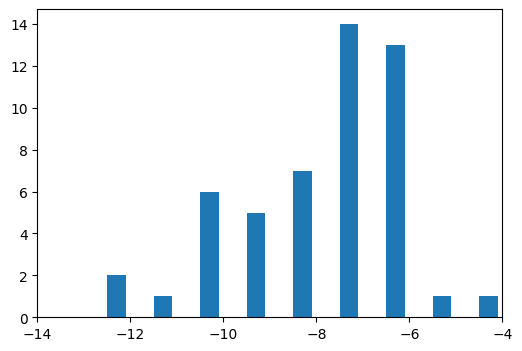

In [11]:
trial_groups_initial = [
    range(50),
    [],
]
trial_groups_initial[1] = [trial for trial in range(50) if not trial in trial_groups_initial[0]]


fig, ax = plt.subplots(1, 1)
fig.set_size_inches(6, 4)


bins = np.arange(-15, 0)
centers = (bins[:-1] + bins[1:]) / 2
bin_width = bins[1] - bins[0]

h0, _ = np.histogram(g_stds[trial_groups_initial[0]], bins=bins)
h1, _ = np.histogram(g_stds[trial_groups_initial[1]], bins=bins)

offset = bin_width * 0.2

ax.bar(centers + offset, h0, width=bin_width*0.4)
ax.bar(centers - offset, h1, width=bin_width*0.4)

ax.set_xlim(-14, -4)

print(g_stds[trial_groups_initial[0]].mean(), g_stds[trial_groups_initial[0]].std())
print(g_stds[trial_groups_initial[1]].mean(), g_stds[trial_groups_initial[1]].std())

-8.091188298976864 1.8426299016218874
-8.029716030269222 1.7568857506081155


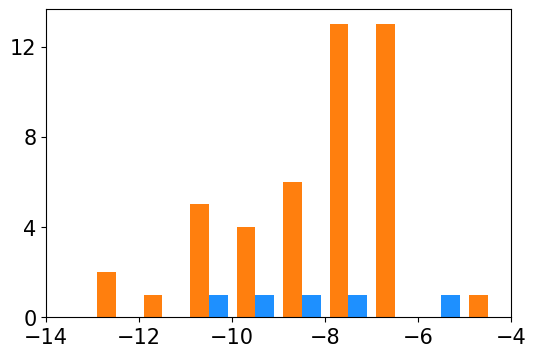

In [13]:
trial_groups_initial = [
    [7, 25, 26, 28, 29],
    [],
]
trial_groups_initial[1] = [trial for trial in range(50) if not trial in trial_groups_initial[0]]


fig, ax = plt.subplots(1, 1)
fig.set_size_inches(6, 4)


bins = np.arange(-15, 0)
centers = (bins[:-1] + bins[1:]) / 2
bin_width = bins[1] - bins[0]

h0, _ = np.histogram(g_stds[trial_groups_initial[0]], bins=bins)
h1, _ = np.histogram(g_stds[trial_groups_initial[1]], bins=bins)

offset = bin_width * 0.2

ax.bar(centers + offset, h0, width=bin_width*0.4, color="#1E90FF")
ax.bar(centers - offset, h1, width=bin_width*0.4, color="tab:orange")

ax.set_xlim(-14, -4)

ax.set_xticks(range(-14, -2, 2))
ax.tick_params(axis='x', labelsize=15)
ax.set_yticks(range(0, 13, 4))
ax.tick_params(axis='y', labelsize=15)

print(g_stds[trial_groups_initial[0]].mean(), g_stds[trial_groups_initial[0]].std())
print(g_stds[trial_groups_initial[1]].mean(), g_stds[trial_groups_initial[1]].std())

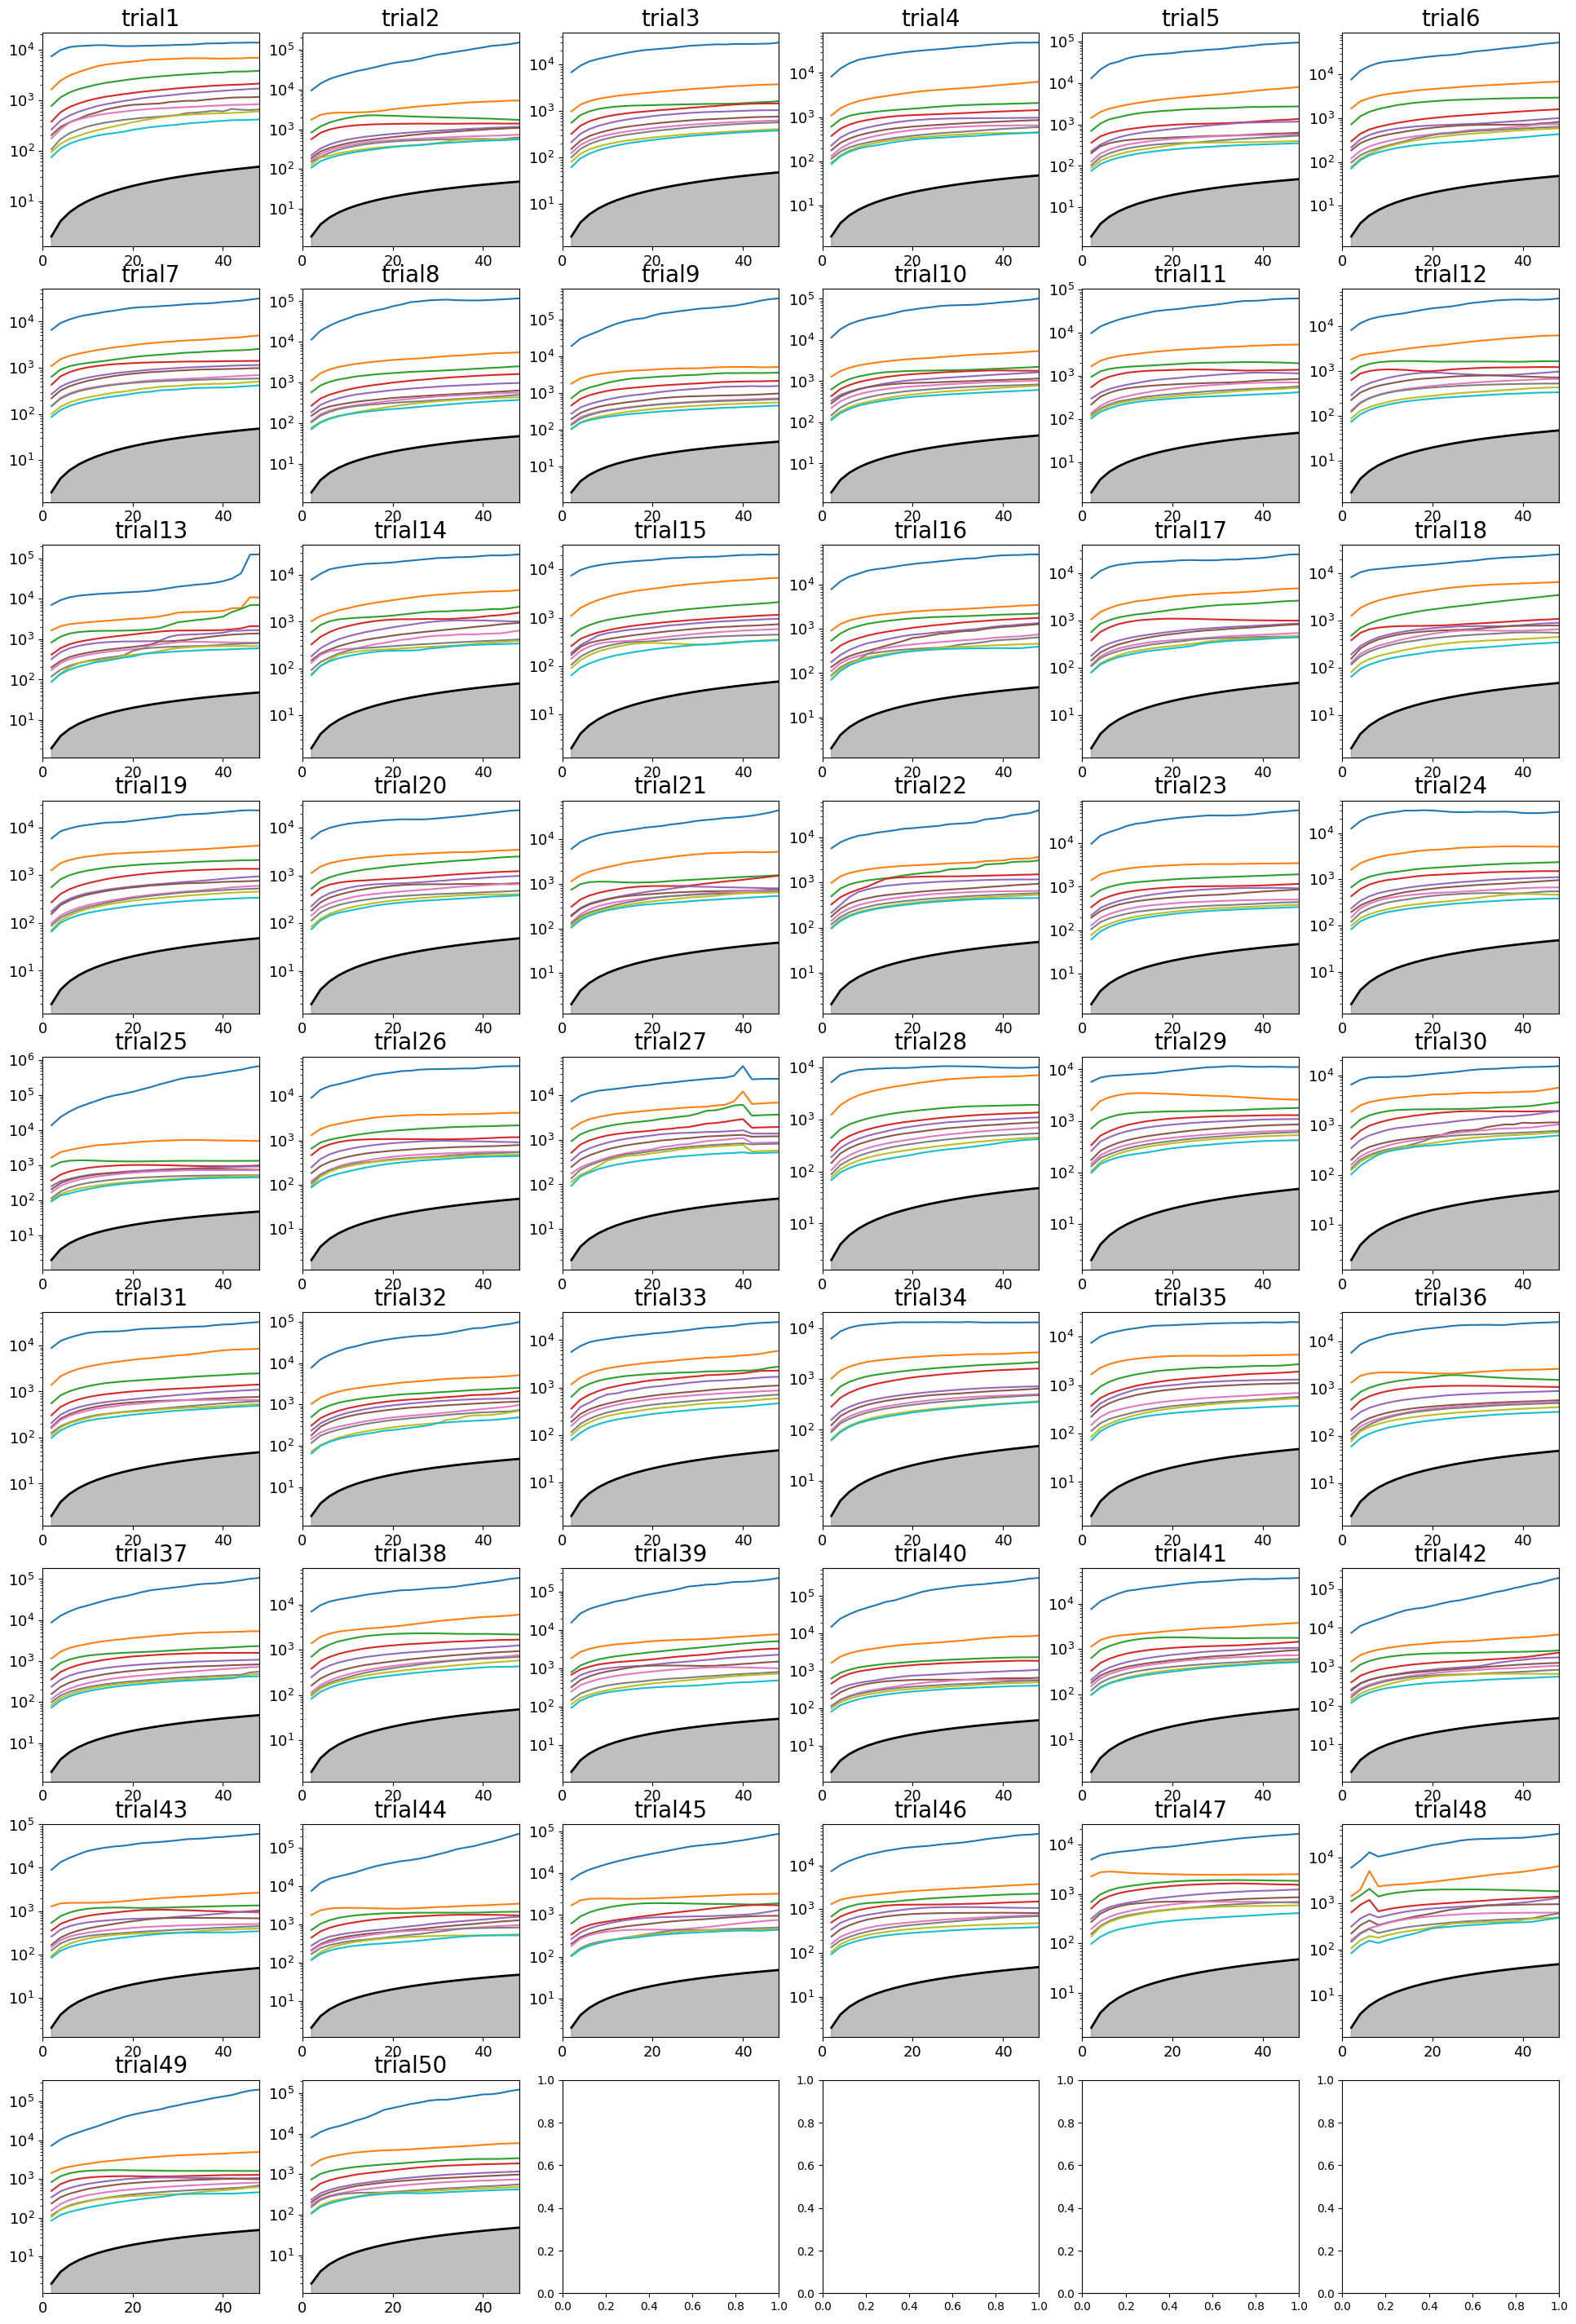

In [16]:
fig, ax = plt.subplots(9, 6)
fig.set_size_inches(24, 36)

for trial in range(len(trajs)):
    plot_implied_timescales(ax[trial//6, trial%6], msm_models[trial][n_clusters[trial]])
    ax[trial//6, trial%6].set_title(f"trial{trial+1}", size=20)
    ax[trial//6, trial%6].tick_params(axis='x', labelsize=13)
    ax[trial//6, trial%6].tick_params(axis='y', labelsize=13)